In [1]:
from scipy.interpolate import interp1d
import matplotlib.pyplot as plt
from pyilc import fg
import pyccl as ccl
import healpy as hp
import numpy as np
import sacc
import os

In [2]:
cosmo = ccl.Cosmology(Omega_c=0.2610, Omega_b=0.04920, h=0.6762, sigma8=0.8149, n_s=0.9709)

### Load Data

In [3]:
sacc_file = "/mnt/extraspace/waylanda/outputs_DESY3_NPIPEnu/cls_cov.fits"
s = sacc.Sacc.load_fits(sacc_file)

s.keep_selection(ell__gt=30, ell__lt=2*2048)
shears = [
    "DESY3wl__0",
    "DESY3wl__1",
    "DESY3wl__2",
    "DESY3wl__3",
]
CMB = [
    "Planck__NPIPEnu100",
    "Planck__NPIPEnu143",
    "Planck__NPIPEnu217",
    "Planck__NPIPEnu353",
    "Planck__NPIPEnu545",
    "Planck__NPIPEnu857",
]
freqs = [int(tr.split("nu")[-1]) for tr in CMB]

n_wlbins = len(shears)
n_freqs = len(CMB)

Assuming data rows are in the correct order as it was before version 1.0.


In [4]:
to_keep = []
for i, shear1 in enumerate(shears):
    for shear2 in shears[i:]:
        #print(shear1, shear2)
        to_keep.append(s.indices("cl_ee", tracers=(shear1, shear2)))
    for cmb in CMB:
        ell__lt = 10000 if not "857" in cmb else 300
        idx = s.indices("cl_0e", tracers=(shear1, cmb), ell__lt=ell__lt)
        if len(idx) == 0:
            print("Index was empty, flipping order")
            idx = s.indices("cl_0e", tracers=(cmb, shear1), ell__lt=ell__lt)
        to_keep.append(idx)
to_keep = np.concatenate(to_keep)
s.keep_indices(to_keep)
lb = s.get_ell_cl("cl_ee", shears[0], shears[0])[0]
n_bins = len(lb)

In [5]:
# Get bandpower windows
bpws = {}

# WL-WL
for i, shear1 in enumerate(shears):
    for shear2 in shears[i:]:
        idx = s.indices("cl_ee", tracers=(shear1, shear2))
        if len(idx) == 0:
            idx = s.indices("cl_ee", tracers=(shear2, shear1))
        bpw = s.get_bandpower_windows(idx)
        bpws[(shear1, shear2)] = bpw

# WL-Planck
for wltracer in shears:
    for cmb in CMB:
        idx = s.indices("cl_0e", tracers=(wltracer, cmb))
        if len(idx) == 0:
            idx = s.indices("cl_0e", tracers=(cmb, wltracer))
        bpw = s.get_bandpower_windows(idx)
        bpws[(wltracer, cmb)] = bpw

### Beams

In [6]:
fwhm = {
    "Planck__NPIPEnu030": 32.29,
    "Planck__NPIPEnu044": 27.94,
    "Planck__NPIPEnu070": 13.08,
    "Planck__NPIPEnu100": 9.66,
    "Planck__NPIPEnu143": 7.22,
    "Planck__NPIPEnu217": 4.90,
    "Planck__NPIPEnu353": 4.92,
    "Planck__NPIPEnu545": 4.67,
    "Planck__NPIPEnu857": 4.22,
}
nside = 2048
lmax = 3*nside-1
pixwin = hp.pixwin(nside, lmax=lmax)
bls = {
    band: hp.gauss_beam(fwhm=np.deg2rad(fwhm / 60.0), lmax=lmax)
    for band, fwhm in fwhm.items()
}
blvec = []
for tr1, tr2 in s.get_tracer_combinations():
    if tr1.startswith("DESY3wl") and tr2.startswith("DESY3wl"):
        cltype = "cl_ee"
    else:
        cltype = "cl_0e"

    l, _ = s.get_ell_cl(cltype, tr1, tr2)
    bl = np.ones(len(l))
    #print(len(l))
    if "Planck" in tr1:
        idx = s.indices("cl_0e", tracers=(tr1, tr2))
        bpw = s.get_bandpower_windows(idx).weight
        bl *= np.einsum("ij,i->j", bpw, bls[tr1] * pixwin)
    if "Planck" in tr2:
        idx = s.indices("cl_0e", tracers=(tr1, tr2))
        bpw = s.get_bandpower_windows(idx).weight
        bl *= np.einsum("ij,i->j", bpw, bls[tr2] * pixwin)
    blvec.append(bl)

bbs = {
    (tr1, tr2): blvec[i]
    for i, (tr1, tr2) in enumerate(s.get_tracer_combinations())
}
blvec = np.concatenate(blvec)

In [7]:
for t1, t2 in s.get_tracer_combinations():
    print(t1, t2)

DESY3wl__0 Planck__NPIPEnu100
DESY3wl__0 Planck__NPIPEnu143
DESY3wl__0 Planck__NPIPEnu217
DESY3wl__0 Planck__NPIPEnu353
DESY3wl__0 Planck__NPIPEnu545
DESY3wl__0 Planck__NPIPEnu857
DESY3wl__1 Planck__NPIPEnu100
DESY3wl__1 Planck__NPIPEnu143
DESY3wl__1 Planck__NPIPEnu217
DESY3wl__1 Planck__NPIPEnu353
DESY3wl__1 Planck__NPIPEnu545
DESY3wl__1 Planck__NPIPEnu857
DESY3wl__2 Planck__NPIPEnu100
DESY3wl__2 Planck__NPIPEnu143
DESY3wl__2 Planck__NPIPEnu217
DESY3wl__2 Planck__NPIPEnu353
DESY3wl__2 Planck__NPIPEnu545
DESY3wl__2 Planck__NPIPEnu857
DESY3wl__3 Planck__NPIPEnu100
DESY3wl__3 Planck__NPIPEnu143
DESY3wl__3 Planck__NPIPEnu217
DESY3wl__3 Planck__NPIPEnu353
DESY3wl__3 Planck__NPIPEnu545
DESY3wl__3 Planck__NPIPEnu857
DESY3wl__0 DESY3wl__0
DESY3wl__0 DESY3wl__1
DESY3wl__0 DESY3wl__2
DESY3wl__0 DESY3wl__3
DESY3wl__1 DESY3wl__1
DESY3wl__1 DESY3wl__2
DESY3wl__1 DESY3wl__3
DESY3wl__2 DESY3wl__2
DESY3wl__2 DESY3wl__3
DESY3wl__3 DESY3wl__3


### SEDs

In [8]:
# Load the SEDs
sed_path = ("/mnt/users/waylanda/tSZxWL_project/component_separation/pyilc/data")

tSZ = fg.get_mix_bandpassed(
    [
        (
            f"{sed_path}/HFI_BANDPASS_F{freq:03d}_reformat.txt"
            if freq >= 100
            else f"{sed_path}/LFI_BANDPASS_F{freq:03d}_reformat.txt"
        )
        for freq in freqs
    ],
    comp="tSZ",
)
tSZs = {}
for wltracer in shears:
    for i, freq in enumerate(freqs):
        tSZs[(wltracer, f"Planck__NPIPEnu{freq}")] = tSZ[i]

In [9]:
import generate_SEDs as gsed

cib_snu, _ = gsed.normalize_and_integrate_sed(
    gsed.snu_arr,
    gsed.bps,
    gsed.redshifts,
    gsed.freq_rest_hz,
    gsed.freq_ghz,
    cosmo,
)
unit_K_to_MJy_per_sr = {
    100: 244.1,
    143: 371.74,
    217: 483.69,
    353: 287.45,
    545: 58.04,
    857: 2.27,
}
# https://arxiv.org/pdf/1309.0382
color_corr = {
   100: 1.076,
   143: 1.017,
   217: 1.119,
   353: 1.097,
   545: 1.068,
   857: 0.995,
}

wl_tracers_ccl = {
    wltracer: ccl.WeakLensingTracer(cosmo, dndz=(s.tracers[wltracer].z, s.tracers[wltracer].nz))
    for wltracer in shears
}

CIBs = {}
for freq in freqs:
    for wltracer in shears:
        z = s.tracers[wltracer].z
        chis = ccl.comoving_radial_distance(cosmo, 1 / (1 + z))
        W = wl_tracers_ccl[wltracer].get_kernel(chis)
        
        snu_interp = interp1d(
            gsed.redshifts,
            cib_snu[freq],
            kind="linear",
            bounds_error=False,
            fill_value="extrapolate",
        )
        snu = snu_interp(z)

        effective_snu = np.trapz(snu * (W * chis**2), z) / np.trapz(W * chis**2, z)

        CIBs[wltracer, f"Planck__NPIPEnu{freq}"] = (
            effective_snu / 1e6 / unit_K_to_MJy_per_sr[freq] * 1e6 * color_corr[freq]
        )

/tmp/ipykernel_3948968/2895078506.py:50: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  effective_snu = np.trapz(snu * (W * chis**2), z) / np.trapz(W * chis**2, z)


### Extract Covariance

In [10]:
idx_cross = []
idx_ss = []
ordering = []
wl_pairs = []

# WL–WL
for i, shear1 in enumerate(shears):
    for shear2 in shears[i:]:
        idx = s.indices("cl_ee", tracers=(shear1, shear2))
        if len(idx) == 0:
            idx = s.indices("cl_ee", tracers=(shear2, shear1))
        idx_ss.append(idx)
        wl_pairs.append((shear1, shear2))

# WL–CMB
for shear in shears:
    for cmb in CMB:
        idx = s.indices("cl_0e", tracers=(shear, cmb))
        if len(idx) == 0:
            print("Index was empty, flipping order")
            idx = s.indices("cl_0e", tracers=(cmb, shear))
            ordering.append((cmb, shear))
        else:
            ordering.append((shear, cmb))
        idx_cross.append(idx)

# Concatenate
idx_ss = np.concatenate(idx_ss)
idx_cross = np.concatenate(idx_cross)

covmat = s.covariance.covmat.copy()
covmat /= blvec[:, None] * blvec[None, :]
ps_vec = s.mean / blvec
covmat = covmat[np.ix_(idx_cross, idx_cross)] * 1e12
ps_vec = ps_vec[idx_cross] * 1e6

# Filter sacc for future uses
s_cross = s.copy()
s_cross.keep_indices(idx_cross)

### Build SED Matrix

In [11]:
S = np.zeros((s_cross.mean.shape[0], 2 * n_bins * n_wlbins))
#print(s_cross.mean.shape)
#print(n_freqs * n_wlbins * n_bins - s_cross.mean.shape[0])

start_idx = 0
for idx_row, (tr1, tr2) in enumerate(ordering):
    print(tr1, tr2)
    # Select only cross-correlations
    if tr1 != tr2:
        # Get CMB and WL tracers
        if "Planck" in tr1:
            wltracer, cmb_tracer = tr2, tr1
        else:
            wltracer, cmb_tracer = tr1, tr2

        l, _ = s_cross.get_ell_cl("cl_0e", tr1, tr2)
        if len(l) == 0:
            l, _ = s_cross.get_ell_cl("cl_0e", tr2, tr1)
        local_nbins = len(l)
        idx_row = np.arange(start_idx, start_idx + local_nbins)
        start_idx += local_nbins

        # Now we define column indices for S
        subS = np.zeros((local_nbins, 2 * n_bins))
        # tSZ part
        try:
            tSZ_sed = tSZs[(wltracer, cmb_tracer)]
        except KeyError:
            tSZ_sed = tSZs[(cmb_tracer, wltracer)]
        mat = np.zeros((local_nbins, n_bins))
        mat[:, :local_nbins] = np.diag(np.ones(local_nbins) * tSZ_sed)
        subS[:, :n_bins] = mat
        # CIB part
        try:
            cib_sed = CIBs[(wltracer, cmb_tracer)]
        except KeyError:
            cib_sed = CIBs[(cmb_tracer, wltracer)]
        mat = np.zeros((local_nbins, n_bins))
        mat[:, :local_nbins] = np.diag(np.ones(local_nbins) * cib_sed)
        subS[:, n_bins:] = mat

        S[
            idx_row,
            shears.index(wltracer)
            * (2 * n_bins) : (shears.index(wltracer) + 1)
            * (2 * n_bins),
        ] = subS

DESY3wl__0 Planck__NPIPEnu100
DESY3wl__0 Planck__NPIPEnu143
DESY3wl__0 Planck__NPIPEnu217
DESY3wl__0 Planck__NPIPEnu353
DESY3wl__0 Planck__NPIPEnu545
DESY3wl__0 Planck__NPIPEnu857
DESY3wl__1 Planck__NPIPEnu100
DESY3wl__1 Planck__NPIPEnu143
DESY3wl__1 Planck__NPIPEnu217
DESY3wl__1 Planck__NPIPEnu353
DESY3wl__1 Planck__NPIPEnu545
DESY3wl__1 Planck__NPIPEnu857
DESY3wl__2 Planck__NPIPEnu100
DESY3wl__2 Planck__NPIPEnu143
DESY3wl__2 Planck__NPIPEnu217
DESY3wl__2 Planck__NPIPEnu353
DESY3wl__2 Planck__NPIPEnu545
DESY3wl__2 Planck__NPIPEnu857
DESY3wl__3 Planck__NPIPEnu100
DESY3wl__3 Planck__NPIPEnu143
DESY3wl__3 Planck__NPIPEnu217
DESY3wl__3 Planck__NPIPEnu353
DESY3wl__3 Planck__NPIPEnu545
DESY3wl__3 Planck__NPIPEnu857


### ML Estimate

In [12]:
# Cross only
inv_covmat = np.linalg.inv(covmat)
covmat_ML = np.linalg.inv(S.T @ inv_covmat @ S)
ps_vec_ML = covmat_ML @ S.T @ inv_covmat @ ps_vec

# Number of WL spectra
n_wl_pairs = len(wl_pairs)

# Total number of WL-WL data points
n_wl_ss = len(idx_ss)

# Build projection matrix
Pmat = np.block(
    [
        [
            np.eye(n_wl_ss),
            np.zeros((n_wl_ss, s_cross.mean.shape[0]))
        ],
        [
            np.zeros((2 * n_bins * n_wlbins, n_wl_ss)),
            covmat_ML @ S.T @ inv_covmat,
        ],
    ]
)

ps_vec_full = s.mean / blvec
for tr1, tr2 in s.get_tracer_combinations():
    print(tr1, tr2)
#print(idx_ss)
ps_vec_full[idx_cross] *= 1e6
ps_vec_full = ps_vec_full[np.concatenate([idx_ss, idx_cross])]
covmat_full = s.covariance.covmat / (blvec[:, None] * blvec[None, :])
covmat_full[np.ix_(idx_cross, idx_cross)] *= 1e12
covmat_full[np.ix_(idx_ss, idx_cross)] *= 1e6
covmat_full[np.ix_(idx_cross, idx_ss)] *= 1e6
covmat_full = covmat_full[
    np.ix_(
        np.concatenate([idx_ss, idx_cross]),
        np.concatenate([idx_ss, idx_cross]),
    )
]
ps_vec_full_ML = Pmat @ ps_vec_full
covmat_full_ML = Pmat @ covmat_full @ Pmat.T

DESY3wl__0 Planck__NPIPEnu100
DESY3wl__0 Planck__NPIPEnu143
DESY3wl__0 Planck__NPIPEnu217
DESY3wl__0 Planck__NPIPEnu353
DESY3wl__0 Planck__NPIPEnu545
DESY3wl__0 Planck__NPIPEnu857
DESY3wl__1 Planck__NPIPEnu100
DESY3wl__1 Planck__NPIPEnu143
DESY3wl__1 Planck__NPIPEnu217
DESY3wl__1 Planck__NPIPEnu353
DESY3wl__1 Planck__NPIPEnu545
DESY3wl__1 Planck__NPIPEnu857
DESY3wl__2 Planck__NPIPEnu100
DESY3wl__2 Planck__NPIPEnu143
DESY3wl__2 Planck__NPIPEnu217
DESY3wl__2 Planck__NPIPEnu353
DESY3wl__2 Planck__NPIPEnu545
DESY3wl__2 Planck__NPIPEnu857
DESY3wl__3 Planck__NPIPEnu100
DESY3wl__3 Planck__NPIPEnu143
DESY3wl__3 Planck__NPIPEnu217
DESY3wl__3 Planck__NPIPEnu353
DESY3wl__3 Planck__NPIPEnu545
DESY3wl__3 Planck__NPIPEnu857
DESY3wl__0 DESY3wl__0
DESY3wl__0 DESY3wl__1
DESY3wl__0 DESY3wl__2
DESY3wl__0 DESY3wl__3
DESY3wl__1 DESY3wl__1
DESY3wl__1 DESY3wl__2
DESY3wl__1 DESY3wl__3
DESY3wl__2 DESY3wl__2
DESY3wl__2 DESY3wl__3
DESY3wl__3 DESY3wl__3


In [13]:
# Ordering should be (γy, γc) for each shear bin
ps_ML = {}
for i, wltracer in enumerate(shears):

    gy_ML = ps_vec_full_ML[n_wl_ss:][
        i * 2 * n_bins : (i + 1) * 2 * n_bins
    ][:n_bins]

    gc_ML = ps_vec_full_ML[n_wl_ss:][
        i * 2 * n_bins : (i + 1) * 2 * n_bins
    ][n_bins:]

    ps_ML[wltracer] = {"gy": gy_ML, "gc": gc_ML}

    err_ML = covmat_ML[
        i * 2 * n_bins : (i + 1) * 2 * n_bins,
        i * 2 * n_bins : (i + 1) * 2 * n_bins,
    ]

    err_gy_ML = np.sqrt(np.diag(err_ML)[:n_bins])
    err_gc_ML = np.sqrt(np.diag(err_ML)[n_bins:])

    ps_ML[wltracer, "err"] = {"gy": err_gy_ML, "gc": err_gc_ML}

### Plot

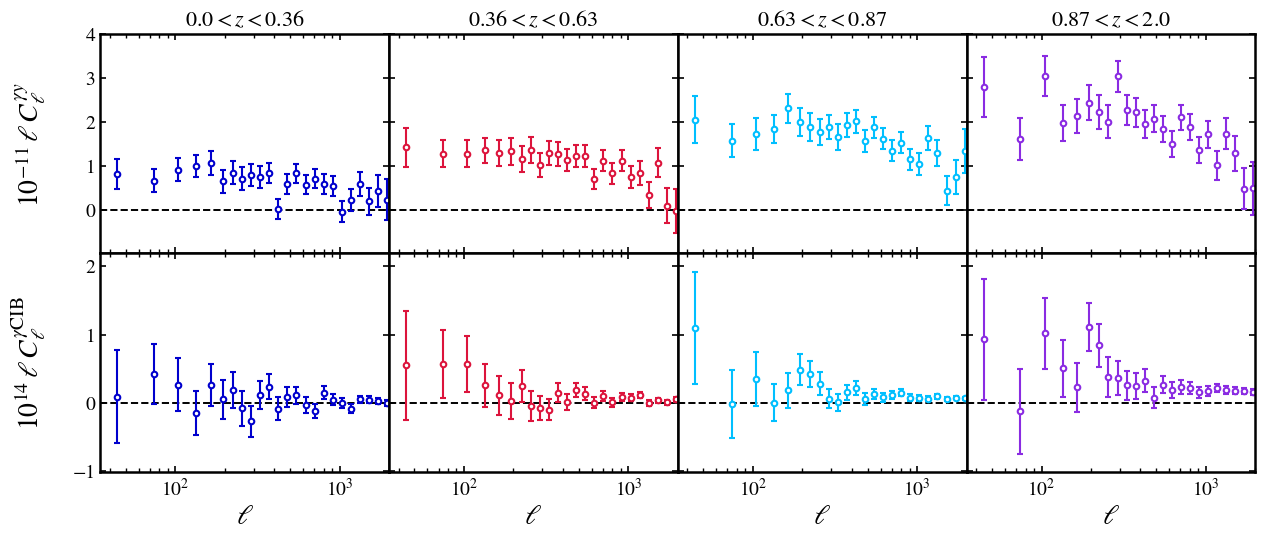

In [ ]:
colours = {
    "DESY3wl__0": "mediumblue",
    "DESY3wl__1": "crimson",
    "DESY3wl__2": "deepskyblue",
    "DESY3wl__3": "blueviolet",
}

shift_amp = 5.0
shifts = {
    "DESY3wl__0": -1.5 * shift_amp,
    "DESY3wl__1": -0.5 * shift_amp,
    "DESY3wl__2": 0.5 * shift_amp,
    "DESY3wl__3": 1.5 * shift_amp,
}

labels = {
    "DESY3wl__0": r"Bin 0",
    "DESY3wl__1": r"Bin 1",
    "DESY3wl__2": r"Bin 2",
    "DESY3wl__3": r"Bin 3",
}

lims = {
    "gc": (-0.8e14, 2.2e14), 
    "gy": (-3e-11, 6.5e-11),
}

z_ranges = {
    'DESY3wl__0': r"$0.0 < z < 0.36$",
    'DESY3wl__1': r"$0.36 < z < 0.63$",
    'DESY3wl__2': r"$0.63 < z < 0.87$",
    'DESY3wl__3': r"$0.87 < z < 2.0$",
}

plt.rcParams.update({
    "mathtext.fontset": "stix", 
    "font.family": "STIXGeneral",
    "font.size": 14,
    "axes.linewidth": 1.8,
})

fac = lb
scale = {"gc": 1e-14, "gy": 1e11}

yticks = {
    "gc": np.array([-1.0, 0.0, 1.0, 2.0]), 
    "gy": np.array([-1.0, 0.0, 1.0, 2.0, 3.0, 4.0]), 
}

fig, axes = plt.subplots(
    2, 4, figsize=(3.2*4, 2.25*2.5),
    sharex=True, sharey='row',
    gridspec_kw={'wspace': 0, 'hspace': 0}
)

ell_max = 2000
row_limits = {}
for type in ["gy", "gc"]:
    all_y = []
    for wltracer in shears:
        mask = lb < ell_max
        fac_masked = fac[mask]
        y = ps_ML[wltracer][type][mask] * fac_masked * scale[type]
        err = ps_ML[wltracer, "err"][type][mask] * fac_masked * scale[type]
        all_y.append(y - err)
        all_y.append(y + err)

    all_y = np.concatenate(all_y)
    ymin, ymax = np.min(all_y), np.max(all_y)
    pad = 0.1 * (ymax - ymin)
    row_limits[type] = (ymin - pad, ymax + pad)


for col, wltracer in enumerate(shears):
    for row, type in enumerate(["gy", "gc"]):
        ax = axes[row, col]
        ax.axhline(0, color="k", ls="--", lw=1.4)

        ell_max = 2000
        mask = lb < ell_max
        x = lb[mask]
        fac_masked = fac[mask]
        y = ps_ML[wltracer][type][mask] * fac_masked * scale[type]
        err = ps_ML[wltracer, "err"][type][mask] * fac_masked * scale[type]

        ax.errorbar(
            x,
            y,
            yerr=err,
            color=colours[wltracer],
            fmt="o",
            markersize=4,
            markerfacecolor="white",
            markeredgewidth=1.5,
            elinewidth=1.5,
            capsize=2,
        )

        ax.set_xlim(35, ell_max)
        ax.set_xscale('log')
        ax.set_ylim(row_limits[type])
        ax.set_yticks(yticks[type])
        ax.tick_params(which='major', direction='in', length=4, width=1.2, top=True, right=True)
        ax.tick_params(which='minor', direction='in', length=3, width=1.0, top=True, right=True)

        if row == 0:
            ax.set_title(z_ranges[wltracer], fontsize=16)

        if col == 0:
            ax.yaxis.set_label_coords(-0.18, 0.5)
            if type == "gy":
                ax.set_ylabel(r"$10^{-11}\,\ell\,C_\ell^{\gamma y}$", fontsize=20)
            else:
                ax.set_ylabel(r"$10^{14}\,\ell\,C_\ell^{\gamma \mathrm{CIB}}$", fontsize=20)

        if row == 1:
            ax.set_xlabel(r"$\ell$", fontsize=20)

        if row == 0:
            current_yticks = ax.get_yticks()
            ax.set_yticks(current_yticks[1:])

plt.tight_layout()
plt.savefig("plots/mlbr_spectra.pdf")
plt.show()

### Write To SACC File

In [20]:
s_gamma_y = sacc.Sacc()

# Add WL tracers
for wltracer in shears:
    tr = s.tracers[wltracer]
    s_gamma_y.add_tracer(
        "NZ",
        wltracer,
        quantity="galaxy_shear",
        spin=2,
        z=tr.z,
        nz=tr.nz
    )

# Add tSZ tracer
s_gamma_y.add_tracer(
        "Map",
        "tSZ",
        quantity="cmb_tSZ",
        spin=0,
        ell=lb,
        beam=np.ones_like(lb),
    )

data_vector = []
kept_indices = []
offset = 0

# WL auto- and cross-correlations
for i, shear1 in enumerate(shears):
    for shear2 in shears[i:]:
        ell, cl = s.get_ell_cl("cl_ee", shear1, shear2)
        nb = len(cl)
        inds = np.arange(offset, offset + nb)
        cl_ml = ps_vec_full_ML[inds]
        wins = bpws[(shear1, shear2)]
        s_gamma_y.add_ell_cl("cl_ee", shear1, shear2, ell, cl_ml, window=wins)
        data_vector.append(cl_ml)
        kept_indices.extend(inds)
        offset += nb

# WL-tSZ cross-correlations
for i, wltracer in enumerate(shears):
    nb = len(lb)
    inds_y = np.arange(offset, offset + nb)
    cl_ml = ps_vec_full_ML[inds_y]
    bpw_ref = bpws[(wltracer, "Planck__NPIPEnu143")] # Reference Planck band
    wins = bpw_ref 
    s_gamma_y.add_ell_cl( "cl_0e", wltracer, "tSZ", lb, cl_ml, window=wins)
    data_vector.append(cl_ml)
    kept_indices.extend(inds_y)
    offset += nb # Move onto the next gamma–y
    offset += nb # Skip gamma–CIB

kept_indices = np.array(kept_indices)
cov_clean = covmat_full_ML[np.ix_(kept_indices, kept_indices)]
s_gamma_y.add_covariance(cov_clean)
s_gamma_y.save_fits("wl_tsz_no_cib_with_bpws.fits", overwrite=True)

In [ ]:
s_gamma_y_cib = sacc.Sacc()

for wltracer in shears:
    tr = s.tracers[wltracer]
    s_gamma_y_cib.add_tracer(
        "NZ", wltracer,
        quantity="galaxy_shear", spin=2,
        z=tr.z, nz=tr.nz,
    )

s_gamma_y_cib.add_tracer(
    "Map", "tSZ",
    quantity="cmb_tSZ", spin=0,
    ell=lb, beam=np.ones_like(lb),
)

s_gamma_y_cib.add_tracer(
    "Map", "CIB",
    quantity="generic", spin=0,
    ell=lb, beam=np.ones_like(lb),
)

data_vector = []
kept_indices = []
offset = 0

# WL auto- and cross-correlations
for i, shear1 in enumerate(shears):
    for shear2 in shears[i:]:
        ell, cl = s.get_ell_cl("cl_ee", shear1, shear2)
        nb = len(cl)
        inds = np.arange(offset, offset + nb)
        cl_ml = ps_vec_full_ML[inds]
        wins = bpws[(shear1, shear2)]
        s_gamma_y_cib.add_ell_cl("cl_ee", shear1, shear2, ell, cl_ml, window=wins)
        data_vector.append(cl_ml)
        kept_indices.extend(inds)
        offset += nb

# WL-tSZ and WL-CIB cross-correlations
for wltracer in shears:
    nb = len(lb)
    bpw_ref = bpws[(wltracer, "Planck__NPIPEnu143")]  # reference Planck band

    # gamma-y
    inds_y = np.arange(offset, offset + nb)
    cl_y = ps_vec_full_ML[inds_y]
    s_gamma_y_cib.add_ell_cl("cl_0e", wltracer, "tSZ", lb, cl_y, window=bpw_ref)
    data_vector.append(cl_y)
    kept_indices.extend(inds_y)
    offset += nb

    # gamma-CIB
    inds_c = np.arange(offset, offset + nb)
    cl_c = ps_vec_full_ML[inds_c]
    s_gamma_y_cib.add_ell_cl("cl_0e", wltracer, "CIB", lb, cl_c, window=bpw_ref)
    data_vector.append(cl_c)
    kept_indices.extend(inds_c)
    offset += nb

kept_indices = np.array(kept_indices)
data_vector = np.concatenate(data_vector)

cov_clean = covmat_full_ML[np.ix_(kept_indices, kept_indices)]
s_gamma_y_cib.add_covariance(cov_clean)
s_gamma_y_cib.save_fits("wl_tsz_cib.fits", overwrite=True)